In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [21]:
df = pd.read_csv("Mall_Customers.csv")
df.shape
df.head()

,CustomerID,Gender,Age,Annual_Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [22]:
print(df.duplicated().sum())
print(df.isnull().sum())
print(df.describe())

0
CustomerID        0
Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64
       CustomerID         Age  Annual_Income  Spending_Score
count  200.000000  200.000000     200.000000      200.000000
mean   100.500000   38.850000      60.560000       50.200000
std     57.879185   13.969007      26.264721       25.823522
min      1.000000   18.000000      15.000000        1.000000
25%     50.750000   28.750000      41.500000       34.750000
50%    100.500000   36.000000      61.500000       50.000000
75%    150.250000   49.000000      78.000000       73.000000
max    200.000000   70.000000     137.000000       99.000000


In [23]:
print(df.columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score'], dtype='str')


In [31]:
from sklearn.preprocessing import StandardScaler

X = df[["Annual_Income" , "Spending_Score"]]

X_scaled = StandardScaler().fit_transform(X)

print(X_scaled.mean(axis=0))
print(X_scaled.std(axis=0))

[-2.13162821e-16 -1.46549439e-16]
[1. 1.]


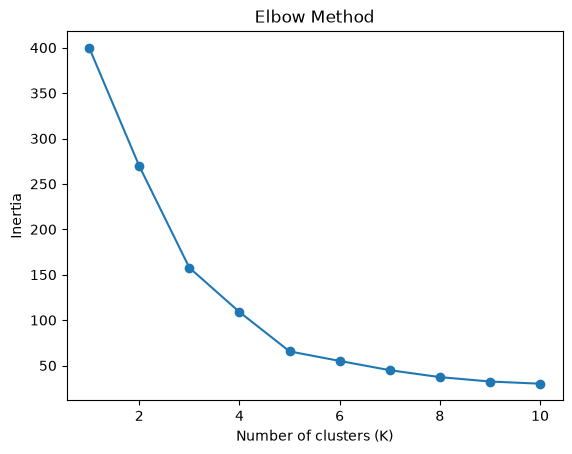

In [ ]:

from sklearn.cluster import KMeans

inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [33]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    print(k, round(silhouette_score(X_scaled, labels), 3))

2 0.321
3 0.467
4 0.494
5 0.555
6 0.54
7 0.528
8 0.455
9 0.457
10 0.443


The customer segmentation model uses K-Means with 5 clusters to group customers by annual income and spending score. The choice of k=5 is based on the elbow method and silhouette score comparisons.

In [38]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)
df.head()

,CustomerID,Gender,Age,Annual_Income,Spending_Score,cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


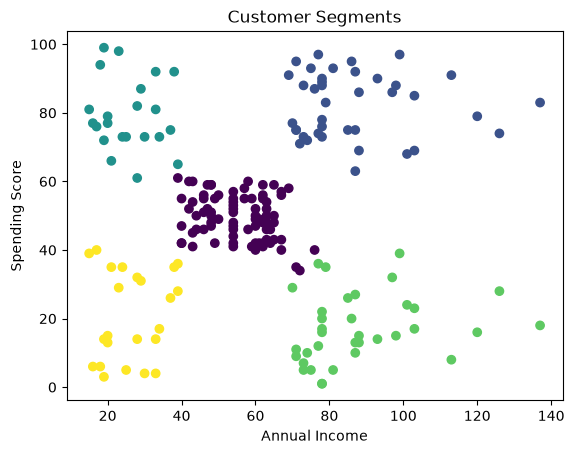

In [39]:
plt.scatter(df["Annual_Income"], df["Spending_Score"],
            c=df["cluster"], cmap="viridis")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segments")
plt.show()

In [46]:
print(df.dtypes)
print(df["cluster"].value_counts())

CustomerID        int64
Gender              str
Age               int64
Annual_Income     int64
Spending_Score    int64
cluster           int32
dtype: object
cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64


In [49]:
print(df.groupby("cluster").mean(numeric_only=True).round(1).drop(columns=["CustomerID" , "Age"]))

         Annual_Income  Spending_Score
cluster                               
0                 55.3            49.5
1                 86.5            82.1
2                 25.7            79.4
3                 88.2            17.1
4                 26.3            20.9


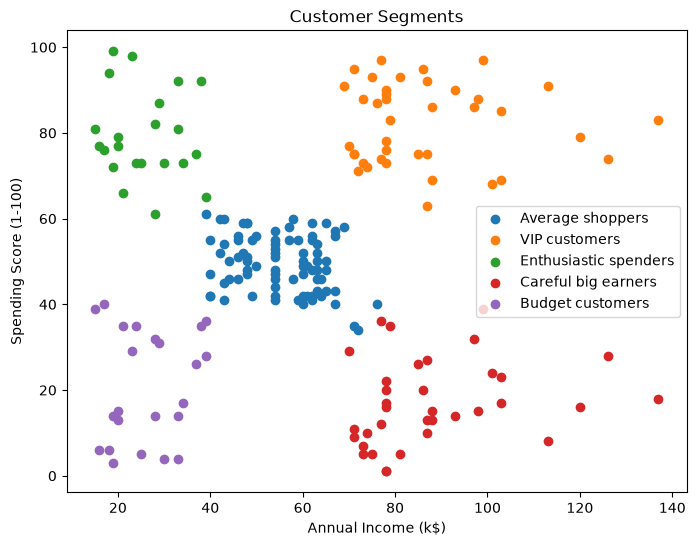

In [50]:


names = {0: "Average shoppers", 1: "VIP customers", 2: "Enthusiastic spenders",
         3: "Careful big earners", 4: "Budget customers"}

plt.figure(figsize=(8, 6))
for c, name in names.items():
    subset = df[df["cluster"] == c]
    plt.scatter(subset["Annual_Income"], subset["Spending_Score"], label=name)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segments")
plt.legend()
plt.show()